Week 4-START

In [22]:
# Import libraries
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

# Load the train and test sets saved in Week 3
PROCESSED_DIR = Path("../data/processed")
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")
print("Train:", train.shape, "| Test:", test.shape)

Train: (1792, 29) | Test: (448, 29)


### 1. Remove duplicates
In train, we drop customers whose copies have different Response labels, then keep one copy of each customer. In test, we only remove exact copies.

In [23]:
# Columns that describe the customer (everything except ID and the target)
feature_columns = [c for c in train.columns if c not in ("ID", "Response")]

# Train: drop duplicate groups whose copies have different Response labels
key = train[feature_columns].apply(lambda s: s.map(str)).agg("|".join, axis=1)
labels_per_group = train.groupby(key)["Response"].transform("nunique")
print("Train rows dropped (conflicting labels):", (labels_per_group > 1).sum())
train = train[labels_per_group == 1]

# Train: keep one copy of each remaining customer
before = len(train)
train = train.drop_duplicates(subset=feature_columns).reset_index(drop=True)
print("Train rows dropped (duplicates):", before - len(train))

# Test: remove exact copies only (same features and same label)
before = len(test)
test = test.drop_duplicates(subset=feature_columns + ["Response"]).reset_index(drop=True)
print("Test rows dropped (duplicates):", before - len(test))

Train rows dropped (conflicting labels): 34
Train rows dropped (duplicates): 144
Test rows dropped (duplicates): 36


### 2. Clean the data
- Drop ID, Z_CostContact, and Z_Revenue because they don't help prediction.
- Group marital status into partnered or not, since Married and Together respond at about 10% while Single, Divorced, and Widow respond at about 22%. Absurd and YOLO become missing.
- Merge "2n Cycle" into Master.
- Treat birth years before 1920 and the $666,666 income as missing.

In [24]:
def clean(df):
    # Drop the identifier and the two constant columns
    df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])

    # Group marital status into partnered (1) or not (0); Absurd and YOLO become missing
    partnered_map = {"Married": 1, "Together": 1,
                     "Single": 0, "Divorced": 0, "Widow": 0, "Alone": 0}
    df["Is_Partnered"] = df["Marital_Status"].map(partnered_map)
    df = df.drop(columns="Marital_Status")

    # 2n Cycle is a master's level degree
    df["Education"] = df["Education"].replace({"2n Cycle": "Master"})

    # Birth years before 1920 are data entry errors
    df.loc[df["Year_Birth"] < 1920, "Year_Birth"] = np.nan

    # $666,666 is a placeholder, not a real income
    df.loc[df["Income"] == 666666, "Income"] = np.nan

    # Convert enrollment date from text to a date
    df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
    return df

train = clean(train)
test = clean(test)
print("Missing values in train after cleaning:")
print(train.isnull().sum()[train.isnull().sum() > 0])

Missing values in train after cleaning:
Year_Birth       2
Income          17
Is_Partnered     2
dtype: int64


### 3. Remove inconsistent rows (train only)
In Week 3 we found 5 rows with spending but zero purchases, and 3 rows where deal purchases exceed total purchases. These numbers contradict each other, so we drop them from train. Test is left unchanged.

In [25]:
spend_columns = ["MntWines", "MntFruits", "MntMeatProducts",
                 "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
purchase_columns = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

total_spend = train[spend_columns].sum(axis=1)
total_purchases = train[purchase_columns].sum(axis=1)

# Rows where spending and purchase counts contradict each other
bad_rows = ((total_spend > 0) & (total_purchases == 0)) | \
           (train["NumDealsPurchases"] > total_purchases)
print("Inconsistent training rows dropped:", bad_rows.sum())
train = train[~bad_rows].reset_index(drop=True)

Inconsistent training rows dropped: 6


### 4. Fill missing values
We did this after all rows are dropped, so the fill values come from the final training set. Income and birth year are filled with the training median, and the partnered flag with the most common value.

In [26]:
# Fill values are learned from the training set only
income_median = train["Income"].median()
birth_median = train["Year_Birth"].median()
partnered_mode = train["Is_Partnered"].mode()[0]

for df in (train, test):
    df["Income"] = df["Income"].fillna(income_median)
    df["Year_Birth"] = df["Year_Birth"].fillna(birth_median)
    df["Is_Partnered"] = df["Is_Partnered"].fillna(partnered_mode).astype(int)

print("Missing values left in train:", train.isnull().sum().sum())
print("Missing values left in test:", test.isnull().sum().sum())

Missing values left in train: 0
Missing values left in test: 0


### 5. Create new features
Age, tenure, total spend, total purchases, and total prior campaigns accepted. In Week 3  prior acceptances and tenure showed as strong signals for Response. Year_Birth and Dt_Customer are dropped after Age and Tenure are created. A Children column is not created because Kidhome and Teenhome affect response differently.

In [27]:
campaign_columns = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
                    "AcceptedCmp4", "AcceptedCmp5"]

# Reference date = latest enrollment in train (same date used for test)
reference_date = train["Dt_Customer"].max()

def add_features(df):
    df["Age"] = reference_date.year - df["Year_Birth"]
    df["Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days
    df["Total_Spend"] = df[spend_columns].sum(axis=1)
    df["Total_Purchases"] = df[purchase_columns].sum(axis=1)
    df["Total_Prev_Accepted"] = df[campaign_columns].sum(axis=1)
    # Year_Birth and Dt_Customer are replaced by Age and Tenure_Days
    return df.drop(columns=["Year_Birth", "Dt_Customer"])

train = add_features(train)
test = add_features(test)
train[["Age", "Tenure_Days", "Total_Spend", "Total_Purchases",
       "Total_Prev_Accepted"]].describe().round(1)

,Age,Tenure_Days,Total_Spend,Total_Purchases,Total_Prev_Accepted
count,1608.0,1608.0,1608.0,1608.0,1608.0
mean,45.3,352.5,622.9,12.7,0.3
std,11.7,201.4,609.6,7.2,0.7
min,18.0,0.0,8.0,1.0,0.0
25%,37.0,180.0,70.0,6.0,0.0
50%,44.0,352.0,411.0,12.0,0.0
75%,55.0,525.0,1079.2,19.0,0.0
max,74.0,699.0,2524.0,32.0,4.0


### 6. Log transform
In Week 3 we saw the spending columns, NumDealsPurchases, and NumCatalogPurchases are right skewed (skew above 1). A log transform reduces the effect of very large values without removing real high spenders. Income is not transformed: once the $666,666 placeholder is removed, its skew is only 0.29, and a log transform made it worse (-1.13).

In [28]:
log_columns = ["Total_Spend", "NumDealsPurchases", "NumCatalogPurchases"] + spend_columns

print("Skew before:")
print(train[log_columns].skew().round(2))

for df in (train, test):
    df[log_columns] = np.log1p(df[log_columns])

print("\nSkew after:")
print(train[log_columns].skew().round(2))

Skew before:
Total_Spend            0.81
NumDealsPurchases      2.29
NumCatalogPurchases    2.08
MntWines               1.13
MntFruits              2.07
MntMeatProducts        2.11
MntFishProducts        1.84
MntSweetProducts       2.06
MntGoldProds           1.83
dtype: float64

Skew after:
Total_Spend           -0.39
NumDealsPurchases      0.68
NumCatalogPurchases    0.11
MntWines              -0.58
MntFruits              0.05
MntMeatProducts       -0.12
MntFishProducts       -0.07
MntSweetProducts       0.05
MntGoldProds          -0.37
dtype: float64


### 7. One hot encode education
Each education level becomes its own 0/1 column, so the model doesn't assume equal gaps between degree levels. Basic is dropped and used as the baseline.

In [29]:
# Basic is dropped and becomes the baseline category
train = pd.get_dummies(train, columns=["Education"], prefix="Edu",
                       drop_first=True, dtype=int)
test = pd.get_dummies(test, columns=["Education"], prefix="Edu",
                      drop_first=True, dtype=int)

# Make sure test has exactly the same columns as train
test = test.reindex(columns=train.columns, fill_value=0)
print("Education columns:", [c for c in train.columns if c.startswith("Edu")])

Education columns: ['Edu_Graduation', 'Edu_Master', 'Edu_PhD']


### 8. Standardize
Numeric columns are scaled to mean 0 and standard deviation 1, so features in different units are comparable. 0/1 columns and the target are not scaled. The scaler is fit on train only.

In [30]:
# Binary (0/1) columns and the target are not scaled
binary_columns = [c for c in train.columns if set(train[c].unique()) <= {0, 1}]
scale_columns = [c for c in train.columns if c not in binary_columns]

scaler = StandardScaler()
train[scale_columns] = scaler.fit_transform(train[scale_columns])
test[scale_columns] = scaler.transform(test[scale_columns])

print("Scaled columns:", scale_columns)
train[scale_columns].describe().round(2)

Scaled columns: ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Age', 'Tenure_Days', 'Total_Spend', 'Total_Purchases', 'Total_Prev_Accepted']


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Age,Tenure_Days,Total_Spend,Total_Purchases,Total_Prev_Accepted
count,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00,1608.00
mean,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.35,-0.83,-0.92,-1.72,-2.60,-1.45,-2.65,-1.54,-1.43,-2.44,-2.31,-1.52,-1.32,-1.79,-2.24,-2.35,-1.75,-2.34,-1.62,-0.44
25%,-0.78,-0.83,-0.92,-0.86,-0.82,-0.75,-0.85,-0.71,-0.99,-0.65,-0.82,-0.78,-1.32,-0.87,-0.97,-0.72,-0.86,-0.94,-0.93,-0.44
50%,-0.00,-0.83,-0.92,0.00,0.28,0.02,0.07,0.00,0.02,0.13,0.05,-0.04,0.10,-0.25,0.30,-0.11,-0.00,0.25,-0.09,-0.44
75%,0.78,1.01,0.91,0.90,0.85,0.83,0.84,0.84,0.82,0.71,0.67,0.70,0.76,0.67,0.73,0.83,0.86,0.90,0.88,-0.44
max,5.19,2.86,2.74,1.69,1.44,1.92,2.08,1.79,1.89,2.06,3.64,7.76,3.03,2.20,6.24,2.46,1.72,1.48,2.69,5.31


# Week 5 – Feature Engineering, Data Augmentation, Dimensionality Reduction
### A. Combined features
We built five candidate features from two or more fields:
- **Household_Size** = 1 + Is_Partnered + Kidhome + Teenhome
- **Lives_Alone** = single (not partnered) with no children at home
- **Income_per_Person** = Income / household size
- **Catalog_Share** = catalog purchases / total purchases (channel preference)
- **Deal_Share** = deal purchases / total purchases (price sensitivity)

Week 4 log-transformed and standardized several of the input columns, but ratios and household counts need the original values. So we first reverse those two Week 4 steps, build the features from the original values, and then standardize the new features with a scaler fit on the training set only. We also check that Kidhome and Teenhome don't count the same child twice.

In [31]:
# Additional imports for Week 5
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, learning_curve
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline

In [32]:
# Week 4 replaced several columns with log-transformed and standardized versions.
# Ratios and household counts need the ORIGINAL values, so we reverse those two steps
# (scaling first, then the log) using the Week 4 scaler, which was fit on train only.
def original_values(df):
    raw = df.copy()
    raw[scale_columns] = scaler.inverse_transform(df[scale_columns])
    raw[log_columns] = np.expm1(raw[log_columns])
    return raw

train_raw = original_values(train)
test_raw = original_values(test)

# Check the reversal is exact: count columns must come back as whole numbers
count_columns = ["Kidhome", "Teenhome", "NumCatalogPurchases", "NumDealsPurchases", "Total_Purchases", "Age"]
for raw in (train_raw, test_raw):
    largest_gap = (raw[count_columns] - raw[count_columns].round()).abs().max().max()
    assert largest_gap < 1e-6, largest_gap
    raw[count_columns] = raw[count_columns].round().astype(int)
print("Original values recovered for train and test (largest rounding gap < 0.000001)")

Original values recovered for train and test (largest rounding gap < 0.000001)


In [33]:
# Check: could a child be counted in both Kidhome and Teenhome?
# Kidhome = number of young children, Teenhome = number of teenagers. If they overlapped,
# customers with both would look implausible. Instead their age sits between the two groups,
# as expected for families with one younger and one older child.
children = pd.crosstab(train_raw["Kidhome"], train_raw["Teenhome"], margins=True)
print("Households by number of young children (rows) and teenagers (columns):")
print(children)

group = np.select([(train_raw["Kidhome"] > 0) & (train_raw["Teenhome"] > 0),
                   (train_raw["Kidhome"] > 0), (train_raw["Teenhome"] > 0)],
                  ["Young children and teens", "Young children only", "Teens only"],
                  default="No children")
print("\nMedian customer age by household type:")
print(train_raw.groupby(group)["Age"].agg(customers="count", median_age="median"))

Households by number of young children (rows) and teenagers (columns):
Teenhome    0    1   2   All
Kidhome                     
0         458  446  19   923
1         367  259  21   647
2          16   22   0    38
All       841  727  40  1608

Median customer age by household type:
                          customers  median_age
No children                     458        46.0
Teens only                      465        50.0
Young children and teens        302        48.0
Young children only             383        36.0


In [34]:
# Candidate combined features, built from the ORIGINAL values (not logged or scaled)
def candidate_features(raw):
    household = 1 + raw["Is_Partnered"] + raw["Kidhome"] + raw["Teenhome"]
    purchases = raw["Total_Purchases"].replace(0, np.nan)
    return pd.DataFrame({
        "Household_Size": household,                                    # customer + partner + children
        "Lives_Alone": ((raw["Is_Partnered"] == 0) &                    # single with no children at home
                        (raw["Kidhome"] + raw["Teenhome"] == 0)).astype(int),
        "Income_per_Person": raw["Income"] / household,                 # income spread across the household
        "Catalog_Share": raw["NumCatalogPurchases"] / purchases,        # channel preference
        "Deal_Share": raw["NumDealsPurchases"] / purchases,             # price sensitivity
    }, index=raw.index)

new_train = candidate_features(train_raw)
new_test = candidate_features(test_raw)
candidate_features_list = list(new_train.columns)

# One test customer has 0 recorded purchases, so the shares are undefined.
# Fill with the training median (learned from train only).
share_columns = ["Catalog_Share", "Deal_Share"]
print("Test rows with 0 purchases (shares filled):", int(new_test["Catalog_Share"].isna().sum()))
new_test[share_columns] = new_test[share_columns].fillna(new_train[share_columns].median())

# Standardize the four non-binary features the same way as Week 4 (scaler fit on train only)
new_scale_columns = ["Household_Size", "Income_per_Person", "Catalog_Share", "Deal_Share"]
new_scaler = StandardScaler()
new_train[new_scale_columns] = new_scaler.fit_transform(new_train[new_scale_columns])
new_test[new_scale_columns] = new_scaler.transform(new_test[new_scale_columns])

train = pd.concat([train, new_train], axis=1)
test = pd.concat([test, new_test], axis=1)
candidate_features = candidate_features_list

# Why Lives_Alone: response is not additive. Single customers with no children respond
# far more than either "single" or "no children" alone would suggest.
print("\nResponse rate (%) by partnered status and number of children:")
print((train_raw.pivot_table(index="Is_Partnered", columns=train_raw["Kidhome"] + train_raw["Teenhome"],
                             values="Response", aggfunc="mean") * 100).round(1))

# Exact duplicate information: is a column an exact sum of other columns (original values)?
# If the rank does not increase when the column is added, it adds no new linear information.
def adds_new_information(new_values, parts):
    base = np.column_stack([np.ones(len(train_raw))] + [train_raw[p] for p in parts])
    return np.linalg.matrix_rank(np.column_stack([base, new_values])) > np.linalg.matrix_rank(base)

household_raw = 1 + train_raw["Is_Partnered"] + train_raw["Kidhome"] + train_raw["Teenhome"]
print("\nAdds new linear information beyond its parts?")
print("  Household_Size vs Is_Partnered + Kidhome + Teenhome:",
      adds_new_information(household_raw, ["Is_Partnered", "Kidhome", "Teenhome"]))
print("  Total_Purchases (Week 4) vs web + catalog + store:",
      adds_new_information(train_raw["Total_Purchases"], purchase_columns))
print("  Total_Prev_Accepted (Week 4) vs the five campaign flags:",
      adds_new_information(train_raw["Total_Prev_Accepted"], campaign_columns))

Test rows with 0 purchases (shares filled): 1

Response rate (%) by partnered status and number of children:
                 0     1     2    3
Is_Partnered                       
0             41.2  13.9  15.8  5.9
1             15.9   8.5   7.0  3.8

Adds new linear information beyond its parts?
  Household_Size vs Is_Partnered + Kidhome + Teenhome: False
  Total_Purchases (Week 4) vs web + catalog + store: False
  Total_Prev_Accepted (Week 4) vs the five campaign flags: False


### B. Which combined features add value?
To see whether each candidate improved predictions, we added it on its own to the 30 Week 4 features and scored the result with 5-fold stratified cross-validation repeated 3 times (15 folds). We ran this on the **training set only**, so the test set stays untouched for the final evaluation.

We used a simple logistic regression as a consistent yardstick, not as the final model. We chose PR-AUC as the main metric because only 14.6% of training customers responded, which makes accuracy misleading. Random guessing would score a PR-AUC of about 0.15.

In [35]:
# Helper: cross-validation on the TRAINING SET ONLY (the test set stays untouched)
# 5 folds x 3 repeats = 15 folds. Every setup uses the same folds, so results can be
# compared fold by fold. Logistic regression is a simple, consistent yardstick here,
# not the final model.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
X_all = train.drop(columns="Response")
y = train["Response"]
fold_pr = {}

def cv_scores(columns, label, model=None, n_features=None):
    model = model if model is not None else LogisticRegression(max_iter=2000)
    s = cross_validate(model, X_all[columns], y, cv=cv,
                       scoring={"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"})
    fold_pr[label] = s["test_PR-AUC"]
    return {"setup": label, "features": n_features or len(columns),
            "PR-AUC": round(s["test_PR-AUC"].mean(), 3),
            "PR-AUC sd": round(s["test_PR-AUC"].std(), 3),
            "ROC-AUC": round(s["test_ROC-AUC"].mean(), 3)}

def vs(label, reference):
    diff = fold_pr[label] - fold_pr[reference]
    return round(diff.mean(), 3), int((diff > 0).sum())

week4_columns = [c for c in X_all.columns if c not in candidate_features]
print("Response rate in training data:", round(y.mean() * 100, 1), "% (= PR-AUC of random guessing)")

# Test each candidate by adding it alone to the Week 4 features
rows = [cv_scores(week4_columns, "Week 4 features")]
for c in candidate_features:
    rows.append(cv_scores(week4_columns + [c], "+ " + c))
rows[0]["change vs Week 4"], rows[0]["folds improved (of 15)"] = "-", "-"
for r in rows[1:]:
    change, wins = vs(r["setup"], "Week 4 features")
    r["change vs Week 4"], r["folds improved (of 15)"] = f"{change:+.3f}", str(wins)
print(pd.DataFrame(rows).to_string(index=False))

Response rate in training data: 14.6 % (= PR-AUC of random guessing)
              setup  features  PR-AUC  PR-AUC sd  ROC-AUC change vs Week 4 folds improved (of 15)
    Week 4 features        30   0.693      0.065    0.920                -                      -
   + Household_Size        31   0.693      0.065    0.920           +0.000                      9
      + Lives_Alone        31   0.713      0.066    0.926           +0.020                     13
+ Income_per_Person        31   0.726      0.065    0.929           +0.033                     15
    + Catalog_Share        31   0.691      0.067    0.920           -0.002                      3
       + Deal_Share        31   0.694      0.064    0.919           +0.002                     10


**Decision:** we kept **Income_per_Person** and **Lives_Alone**, the only two candidates that improved PR-AUC on most folds.
- We dropped **Household_Size** because it is an exact sum of Is_Partnered, Kidhome, and Teenhome, so it added no new information (+0.000).
- We dropped **Catalog_Share** and **Deal_Share** because they added almost nothing and largely repeat the purchase counts they were built from.

In [36]:
# Keep the two features that add value; drop the rest
keep_features = ["Income_per_Person", "Lives_Alone"]
drop_features = [c for c in candidate_features if c not in keep_features]
train = train.drop(columns=drop_features)
test = test.drop(columns=drop_features)
X_all = X_all.drop(columns=drop_features)
all_columns = list(X_all.columns)
print("Dropped:", drop_features)

final = pd.DataFrame([
    cv_scores(week4_columns, "Week 4 features"),
    cv_scores(all_columns, "Week 4 + Income_per_Person + Lives_Alone"),
])
change, wins = vs("Week 4 + Income_per_Person + Lives_Alone", "Week 4 features")
print(final.to_string(index=False))
print(f"\nChange in PR-AUC: {change:+.3f}, improved on {wins} of 15 folds")

# Why Income_per_Person helps: response rate (%) by quintile, compared with Income alone.
# Quintiles depend only on the order of values, so scaling does not change them.
quintiles = pd.DataFrame({
    col: (train.groupby(pd.qcut(train[col], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]),
                        observed=True)["Response"].mean() * 100).round(1)
    for col in ["Income", "Income_per_Person"]})
print("\nResponse rate (%) by quintile:")
print(quintiles)

Dropped: ['Household_Size', 'Catalog_Share', 'Deal_Share']
                                   setup  features  PR-AUC  PR-AUC sd  ROC-AUC
                         Week 4 features        30   0.693      0.065    0.920
Week 4 + Income_per_Person + Lives_Alone        32   0.725      0.066    0.929

Change in PR-AUC: +0.032, improved on 15 of 15 folds

Response rate (%) by quintile:
              Income  Income_per_Person
Q1 (lowest)     11.2                8.4
Q2              11.8               12.1
Q3               9.9                8.4
Q4              10.6               10.3
Q5 (highest)    29.2               33.5


### C. Synthetic data (SMOTE) and sample size
The training set has 1,608 customers but only 234 responders, so we tested whether adding synthetic responders would improve predictions. We used SMOTE, which creates new responders by placing points between real responders and their nearest responder neighbours.

We compared SMOTE with two alternatives: making no adjustment, and using class weights, which give real responders more weight instead of creating new rows. To avoid leakage, we created synthetic rows **inside each training fold only**, never in the validation folds or the test set.

In [37]:
# Each synthetic responder is placed at a random point on the line between a real
# responder and one of its 5 nearest responder neighbours. 0/1 columns are copied from
# the real responder so they stay 0 or 1.
def smote(X, y, binary_cols, k=5, random_state=42):
    rng = np.random.default_rng(random_state)
    X_min = X[y == 1].to_numpy(dtype=float)
    n_new = int((y == 0).sum() - (y == 1).sum())              # balance the classes 1:1
    _, neighbours = NearestNeighbors(n_neighbors=k + 1).fit(X_min).kneighbors(X_min)
    base = rng.integers(0, len(X_min), n_new)
    partner = neighbours[base, rng.integers(1, k + 1, n_new)]
    synthetic = X_min[base] + rng.random((n_new, 1)) * (X_min[partner] - X_min[base])
    bin_idx = [X.columns.get_loc(c) for c in binary_cols]
    synthetic[:, bin_idx] = X_min[base][:, bin_idx]
    X_new = pd.concat([X, pd.DataFrame(synthetic, columns=X.columns)], ignore_index=True)
    y_new = pd.concat([y, pd.Series(np.ones(n_new, dtype=int))], ignore_index=True)
    return X_new, y_new

# Compare three ways of handling the minority class. Synthetic rows are created ONLY
# inside each training fold, never in the validation fold or the test set.
binary_features = [c for c in all_columns if set(X_all[c].unique()) <= {0, 1}]
methods = ["No adjustment", "Class weights", "SMOTE synthetic data"]
scores = {m: {"PR-AUC": [], "ROC-AUC": [], "Recall": [], "Precision": []} for m in methods}

for fold, (tr, va) in enumerate(cv.split(X_all, y)):
    X_tr, y_tr = X_all.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True)
    X_va, y_va = X_all.iloc[va], y.iloc[va]
    X_sm, y_sm = smote(X_tr, y_tr, binary_features, random_state=fold)
    models = {"No adjustment": LogisticRegression(max_iter=2000).fit(X_tr, y_tr),
              "Class weights": LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_tr, y_tr),
              "SMOTE synthetic data": LogisticRegression(max_iter=2000).fit(X_sm, y_sm)}
    for m, model in models.items():
        p = model.predict_proba(X_va)[:, 1]
        scores[m]["PR-AUC"].append(average_precision_score(y_va, p))
        scores[m]["ROC-AUC"].append(roc_auc_score(y_va, p))
        scores[m]["Recall"].append(recall_score(y_va, p >= 0.5))
        scores[m]["Precision"].append(precision_score(y_va, p >= 0.5))

print(f"Rows in each training fold: {len(X_tr)} real -> {len(X_sm)} after SMOTE "
      f"(responders {y_tr.sum()} -> {y_sm.sum()}, of which {y_sm.sum() - y_tr.sum()} synthetic)")
print("Recall and precision use a 0.5 probability cutoff.\n")
print(pd.DataFrame({m: {k: round(np.mean(v), 3) for k, v in s.items()}
                    for m, s in scores.items()}).T)

Rows in each training fold: 1287 real -> 2198 after SMOTE (responders 188 -> 1099, of which 911 synthetic)
Recall and precision use a 0.5 probability cutoff.

                      PR-AUC  ROC-AUC  Recall  Precision
No adjustment          0.725    0.929   0.543      0.747
Class weights          0.722    0.928   0.842      0.498
SMOTE synthetic data   0.725    0.927   0.839      0.520


**Is the dataset too small?** With only 234 responders, we also tested whether more data would improve results. We trained the same logistic regression on growing shares of each training fold, from 10% to 100%, and scored each version on the same validation folds. If the validation score were still rising at full size, more data would help.

 training rows  responders (approx.)  train PR-AUC  validation PR-AUC  validation sd
           128                    19         0.922              0.617          0.067
           257                    37         0.851              0.666          0.050
           385                    56         0.827              0.682          0.059
           514                    75         0.803              0.700          0.065
           643                    94         0.792              0.703          0.064
           771                   112         0.786              0.710          0.066
           900                   131         0.779              0.713          0.067
          1028                   150         0.775              0.721          0.067
          1157                   168         0.775              0.722          0.068
          1286                   187         0.774              0.725          0.066


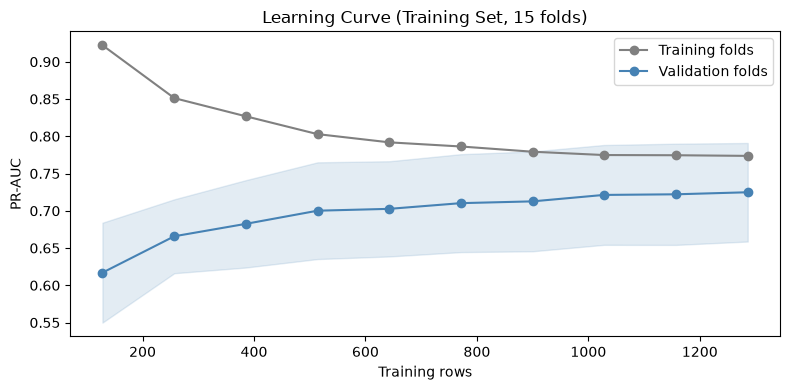


Responders in training: 234 | features: 32 | responders per feature: 7.3
Responders in the test set: 63 of 412


In [38]:
# Is the dataset too small? Learning curve: train on growing shares of each training
# fold and score on the same validation folds. If the validation score is still rising
# steeply at full size, more data would help; if it has levelled off, it would help less.
sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(max_iter=2000), X_all[all_columns], y, cv=cv,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring="average_precision",
    shuffle=True, random_state=42)

curve = pd.DataFrame({"training rows": sizes,
                      "responders (approx.)": (sizes * y.mean()).round().astype(int),
                      "train PR-AUC": train_scores.mean(axis=1).round(3),
                      "validation PR-AUC": val_scores.mean(axis=1).round(3),
                      "validation sd": val_scores.std(axis=1).round(3)})
print(curve.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(sizes, train_scores.mean(axis=1), marker="o", color="grey", label="Training folds")
plt.plot(sizes, val_scores.mean(axis=1), marker="o", color="steelblue", label="Validation folds")
plt.fill_between(sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), color="steelblue", alpha=0.15)
plt.xlabel("Training rows"); plt.ylabel("PR-AUC")
plt.title("Learning Curve (Training Set, 15 folds)"); plt.legend()
plt.tight_layout(); plt.show()

# Responders per feature: a common guideline for logistic regression is at least 10
print("\nResponders in training:", int(y.sum()), "| features:", len(all_columns),
      "| responders per feature:", round(y.sum() / len(all_columns), 1))
print("Responders in the test set:", int(test["Response"].sum()), "of", len(test))

### D. Dimensionality reduction
Three approaches, each compared with the full feature set on the same 15 folds:
1. **Aggregation:** replace the five campaign flags with their total (Total_Prev_Accepted).
2. **Correlation filter:** for each pair with |Spearman rho| >= 0.85, drop the weaker feature.
3. **PCA:** replace the features with principal components (refit inside each fold).

In [39]:
# Approach 1: aggregation. Replace the five campaign flags with their total,
# Total_Prev_Accepted (already in the data since Week 4).
aggregated_columns = [c for c in all_columns if c not in campaign_columns]

# Approach 2: correlation filter. For each pair with |Spearman rho| >= 0.85,
# drop the feature with the weaker single-feature signal.
corr = X_all[all_columns].corr(method="spearman").abs()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename("rho").rename_axis(["feature_1", "feature_2"]).reset_index())
strong = pairs[pairs["rho"] >= 0.85].sort_values("rho", ascending=False)
strength = {c: abs(roc_auc_score(y, X_all[c]) - 0.5) for c in all_columns}
filtered_out = set()
for _, row in strong.iterrows():
    a, b = row["feature_1"], row["feature_2"]
    if a not in filtered_out and b not in filtered_out:
        filtered_out.add(a if strength[a] < strength[b] else b)
filtered_columns = [c for c in all_columns if c not in filtered_out]

print("Approach 1 drops:", campaign_columns)
print("\nApproach 2: pairs with |Spearman rho| >= 0.85")
print(strong.round(2).to_string(index=False))
print("Approach 2 drops:", sorted(filtered_out))

Approach 1 drops: ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']

Approach 2: pairs with |Spearman rho| >= 0.85
          feature_1           feature_2  rho
    MntMeatProducts         Total_Spend 0.94
           MntWines         Total_Spend 0.93
        Total_Spend     Total_Purchases 0.90
NumCatalogPurchases         Total_Spend 0.89
  NumStorePurchases     Total_Purchases 0.89
NumCatalogPurchases     Total_Purchases 0.88
           MntWines     Total_Purchases 0.87
             Income         Total_Spend 0.86
             Income   Income_per_Person 0.86
    MntMeatProducts     Total_Purchases 0.86
    MntMeatProducts NumCatalogPurchases 0.85
Approach 2 drops: ['Income', 'MntMeatProducts', 'MntWines', 'NumCatalogPurchases', 'Total_Purchases']


Components for 80% of variance: 8 of 32
Components for 90% of variance: 13 of 32
Components for 95% of variance: 17 of 32


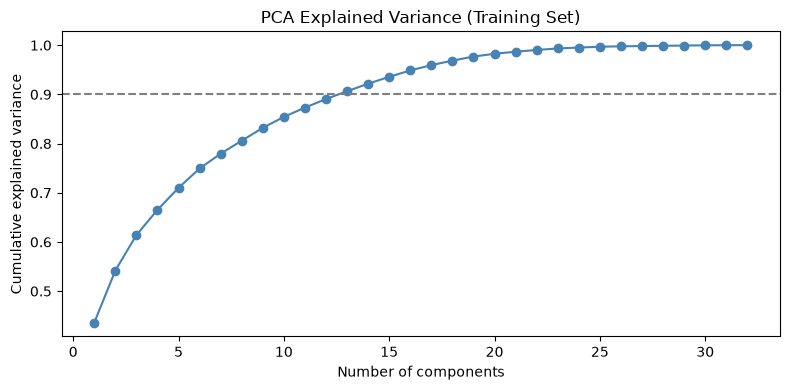

                      setup  features  PR-AUC  PR-AUC sd  ROC-AUC change vs all folds matched or beat (of 15)
               All features        32   0.725      0.066    0.929             -                             -
 1. Campaign flags -> total        27   0.729      0.067    0.930        +0.004                            11
      2. Correlation filter        27   0.711      0.059    0.920        -0.014                             3
3. PCA, 13 components (90%)        13   0.702      0.059    0.915        -0.023                             2
3. PCA, 17 components (95%)        17   0.702      0.063    0.919        -0.023                             1


In [40]:
# Approach 3: PCA. Replace all features with uncorrelated components.
pca = PCA(random_state=42).fit(X_all[all_columns])
cumulative = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.argmax(cumulative >= 0.90) + 1)
n95 = int(np.argmax(cumulative >= 0.95) + 1)
for target in (0.80, 0.90, 0.95):
    print(f"Components for {target:.0%} of variance:", int(np.argmax(cumulative >= target) + 1),
          "of", len(all_columns))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o", color="steelblue")
plt.axhline(0.90, color="grey", linestyle="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance (Training Set)")
plt.tight_layout(); plt.show()

# Compare all approaches on the same folds (PCA is refit inside each fold)
pca_model = lambda n: make_pipeline(PCA(n_components=n, random_state=42),
                                    LogisticRegression(max_iter=2000))
comparison = pd.DataFrame([
    cv_scores(all_columns, "All features"),
    cv_scores(aggregated_columns, "1. Campaign flags -> total"),
    cv_scores(filtered_columns, "2. Correlation filter"),
    cv_scores(all_columns, f"3. PCA, {n90} components (90%)", pca_model(n90), n_features=n90),
    cv_scores(all_columns, f"3. PCA, {n95} components (95%)", pca_model(n95), n_features=n95),
])
comparison["change vs all"] = ["-"] + [f"{vs(s, 'All features')[0]:+.3f}" for s in comparison["setup"][1:]]
comparison["folds matched or beat (of 15)"] = ["-"] + [
    str(int((fold_pr[s] >= fold_pr["All features"]).sum())) for s in comparison["setup"][1:]]
print(comparison.to_string(index=False))

### E. Save model-ready data
Both feature sets are saved for Week 6, with real rows only (no synthetic data).

In [41]:
# Save model-ready data for Week 6 (real rows only; no synthetic data is saved)
# Reduced set = campaign flags replaced by their total (approach 1)
train[all_columns + ["Response"]].to_csv(PROCESSED_DIR / "train_model_full.csv", index=False)
test[all_columns + ["Response"]].to_csv(PROCESSED_DIR / "test_model_full.csv", index=False)
train[aggregated_columns + ["Response"]].to_csv(PROCESSED_DIR / "train_model_reduced.csv", index=False)
test[aggregated_columns + ["Response"]].to_csv(PROCESSED_DIR / "test_model_reduced.csv", index=False)

print("Full set    -> train:", train[all_columns].shape, "| test:", test[all_columns].shape)
print("Reduced set -> train:", train[aggregated_columns].shape, "| test:", test[aggregated_columns].shape)
print("Missing values (train, test):", int(train.isnull().sum().sum()), int(test.isnull().sum().sum()))

Full set    -> train: (1608, 32) | test: (412, 32)
Reduced set -> train: (1608, 27) | test: (412, 27)
Missing values (train, test): 0 0
